In [ ]:
import pandas as pd
import numpy as np
import os
def generate_and_clean_data():
    # 1. Generate Synthetic Sales Dataset for demonstration
    np.random.seed(42)
    n_rows = 5000

    dates = pd.date_range(start='2023-01-01', end='2025-12-31', periods=n_rows)
    categories = ['Electronics', 'Furniture', 'Clothing', 'Office Supplies']
    regions = ['North', 'South', 'East', 'West']

    data = {
        'order_id': [f'ORD-{i:05d}' for i in range(n_rows)],
        'order_date': np.random.choice(dates, n_rows),
        'category': np.random.choice(categories, n_rows),
        'region': np.random.choice(regions, n_rows),
        'quantity': np.random.randint(1, 10, n_rows),
        'unit_price': np.random.uniform(10.0, 500.0, n_rows),
        'discount': np.random.choice([0.0, 0.05, 0.1, 0.2], n_rows, p=[0.6, 0.2, 0.1, 0.1])
    }

    df = pd.DataFrame(data)

    # Introduce intentional missing values and duplicates for cleaning demonstration
    df.loc[df.sample(n=50).index, 'unit_price'] = np.nan
    df = pd.concat([df, df.sample(n=20)], ignore_index=True) # Duplicates

    print(f"Raw dataset shape: {df.shape}")

    # 2. Data Cleaning
    # Handle missing values (Impute numerical median)
    df['unit_price'] = df['unit_price'].fillna(df['unit_price'].median())
    df['quantity'] = df['quantity'].fillna(df['quantity'].median())

    # Remove duplicates
    initial_count = len(df)
    df = df.drop_duplicates()
    print(f"Removed {initial_count - len(df)} duplicate rows.")

    # Date conversion
    df['order_date'] = pd.to_datetime(df['order_date'])

    # 3. Feature Engineering
    df['total_sales'] = df['quantity'] * df['unit_price'] * (1 - df['discount'])
    df['year'] = df['order_date'].dt.year
    df['month'] = df['order_date'].dt.month
    df['quarter'] = df['order_date'].dt.quarter
    df['day_of_week'] = df['order_date'].dt.day_name()

    # Create the 'data' directory if it doesn't already exist
    os.makedirs("data", exist_ok=True)

    # Save cleaned data
    df.to_csv("data/cleaned_sales.csv", index=False)
    print("Cleaned data successfully saved to data/cleaned_sales.csv")
    # Save cleaned data
    df.to_csv('data/cleaned_sales.csv', index=False)
    print("Cleaned data successfully saved to data/cleaned_sales.csv")
    return df

if __name__ == "__main__":
    generate_and_clean_data()

Raw dataset shape: (5020, 7)
Removed 20 duplicate rows.
Cleaned data successfully saved to data/cleaned_sales.csv
Cleaned data successfully saved to data/cleaned_sales.csv


In [ ]:
import sqlite3
import pandas as pd

def run_sql_analysis():
    df = pd.read_csv('data/cleaned_sales.csv')

    # Connect to SQLite
    conn = sqlite3.connect('sales_database.db')
    df.to_sql('sales', conn, if_exists='replace', index=False)

    # Query 1: Total Sales and Profit by Category
    query_category = """
    SELECT category,
           SUM(total_sales) AS total_revenue,
           SUM(quantity) AS total_units_sold,
           AVG(total_sales) AS avg_order_value
    FROM sales
    GROUP BY category
    ORDER BY total_revenue DESC;
    """
    print("--- Category Performance ---")
    print(pd.read_sql(query_category, conn))

    # Query 2: Monthly Sales Trends
    query_monthly = """
    SELECT year, month,
           SUM(total_sales) AS monthly_revenue
    FROM sales
    GROUP BY year, month
    ORDER BY year, month;
    """
    print("\n--- Monthly Trends (First 5 rows) ---")
    print(pd.read_sql(query_monthly, conn).head())

    conn.close()

if __name__ == "__main__":
    run_sql_analysis()

--- Category Performance ---
          category  total_revenue  total_units_sold  avg_order_value
0        Furniture   1.597382e+06              6404      1229.701107
1      Electronics   1.550317e+06              6171      1256.334618
2         Clothing   1.500729e+06              6237      1198.665085
3  Office Supplies   1.485022e+06              6041      1222.240492

--- Monthly Trends (First 5 rows) ---
   year  month  monthly_revenue
0  2023      1    163484.415328
1  2023      2    151081.601939
2  2023      3    154695.036788
3  2023      4    128608.981091
4  2023      5    162343.214243


In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def train_forecast_model():
    df = pd.read_csv('data/cleaned_sales.csv')
    df['order_date'] = pd.to_datetime(df['order_date'])

    # Aggregate monthly
    df['year_month'] = df['order_date'].dt.to_period('M')
    monthly = df.groupby('year_month')['total_sales'].sum().reset_index()
    monthly['year_month'] = monthly['year_month'].dt.to_timestamp()

    # Feature Engineering: Lag Features
    monthly['lag_1'] = monthly['total_sales'].shift(1)
    monthly['lag_2'] = monthly['total_sales'].shift(2)
    monthly['month'] = monthly['year_month'].dt.month
    monthly['year'] = monthly['year_month'].dt.year

    monthly = monthly.dropna().reset_index(drop=True)

    # Train/Test Split (Chronological split: last 6 months for test)
    train = monthly.iloc[:-6]
    test = monthly.iloc[-6:]

    features = ['lag_1', 'lag_2', 'month', 'year']
    X_train, y_train = train[features], train['total_sales']
    X_test, y_test = test[features], test['total_sales']

    # Model Training
    model = RandomForestRegressor(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)

    # Evaluation
    predictions = model.predict(X_test)
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    print(f"Model Evaluation Metrics:")
    print(f"MAE : {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R²  : {r2:.2f}")

    return model

if __name__ == "__main__":
    train_forecast_model()

Model Evaluation Metrics:
MAE : 12636.70
RMSE: 17208.99
R²  : -1.55


In [ ]:
pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 74.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 95.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [ ]:
import sqlite3
import pandas as pd
from google import genai
import os

# 1. Load data and metrics just like your dashboard does
conn = sqlite3.connect('sales_database.db')
df = pd.read_sql('SELECT * FROM sales', conn)
conn.close()

total_rev = df['total_sales'].sum()
total_units = df['quantity'].sum()
avg_order = df['total_sales'].mean()

# 2. Set up Gemini Client (Make sure GEMINI_API_KEY is in Colab Secrets or set here)
os.environ["GEMINI_API_KEY"] = "API_SECRET_KEY"


client = genai.Client(api_key="API_SECRET_KEY")


prompt = f"""
Act as a Senior Business Analyst. Analyze the following verified sales metrics and provide 3 key strategic recommendations to executive management:
- Total Revenue: ${total_rev:,.2f}
- Total Units Sold: {total_units:,}
- Average Order Value: ${avg_order:,.2f}
Keep your insights concise, actionable, and data-driven.
"""

response = client.models.generate_content(
    model='gemini-3.5-flash',
    contents=prompt
)

print("--- AI Executive Insights ---")
print(response.text)

--- AI Executive Insights ---
**Executive Briefing: Sales Performance & Strategic Recommendations**

**Data Summary & Derived Metrics:**
*   **Total Revenue:** $6,133,449.54
*   **Total Units Sold:** 24,853 units (Avg. Price per Unit: ~$246.79)
*   **Average Order Value (AOV):** $1,226.69
*   **Implied Order Volume:** ~5,000 orders (Avg. ~4.97 units per order)

---

### **Strategic Recommendations for Executive Management**

#### **1. Optimize Product Bundling to Push AOV Past the $1,500 Threshold**
* **Insight:** Customers purchase an average of ~5 units per order at a strong AOV of $1,226.69, signaling high purchasing power and trust in the catalog.
* **Action:** Implement dynamic cross-selling algorithms and tiered volume incentives (e.g., "Spend $1,500, get 10% off accessories") at checkout. Focus on attaching higher-margin, complementary products to existing ~5-unit basket structures to expand order value without increasing customer acquisition costs (CAC).

#### **2. Launch a Ded

/tmp/ipykernel_3861/216576253.py:24: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_df = df.set_index('order_date').resample('M')['total_sales'].sum().reset_index()
/tmp/ipykernel_3861/216576253.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


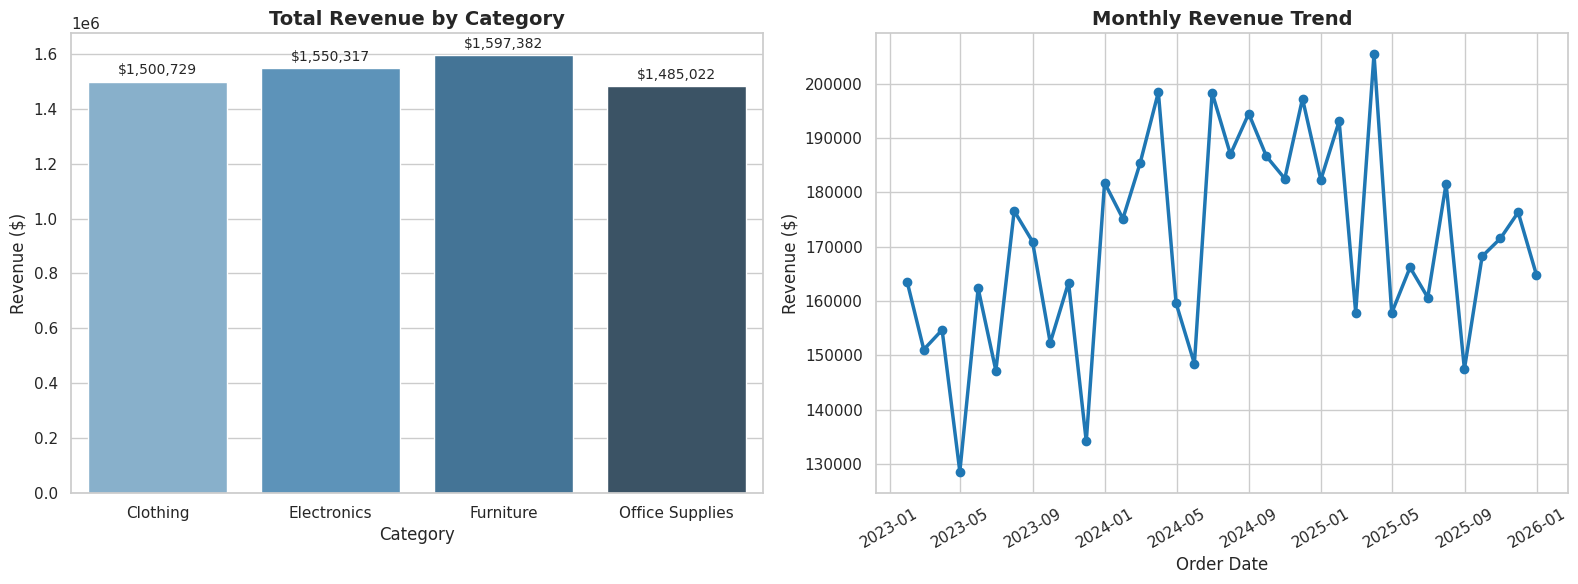


🤖 AI EXECUTIVE INSIGHTS
### **Executive Summary**
With a total revenue of **$6,133,449.54**, **24,853 units sold**, and a strong Average Order Value (AOV) of **$1,226.69** (implying an Average Selling Price of ~$246.79/unit), the business exhibits healthy high-ticket transaction patterns. Revenue is remarkably balanced across all four categories—ranging from **24.21%** (Office Supplies) to **26.04%** (Furniture)—indicating a stable product portfolio but highlighting untapped opportunities for category-specific optimization and cross-selling.

---

### **Strategic Recommendations for Executive Management**

#### **1. Shift Capital Allocation from Revenue Parity to Margin-Driven Optimization**
* **Data Insight:** Revenue is almost evenly split across Furniture ($1.60M / 26.0%), Electronics ($1.55M / 25.3%), Clothing ($1.50M / 24.5%), and Office Supplies ($1.49M / 24.2%). However, top-line revenue parity often masks significant margin disparities (e.g., Clothing typically carries higher 

In [ ]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google import genai
import os

# Set professional styling for charts
sns.set_theme(style="whitegrid")

# 1. Load data from SQLite database
conn = sqlite3.connect('sales_database.db')
df = pd.read_sql('SELECT * FROM sales', conn)
df['order_date'] = pd.to_datetime(df['order_date'])
conn.close()

# Compute key metrics
total_rev = df['total_sales'].sum()
total_units = df['quantity'].sum()
avg_order = df['total_sales'].mean()

# Aggregate data for charts
category_df = df.groupby('category')['total_sales'].sum().reset_index()
monthly_df = df.set_index('order_date').resample('M')['total_sales'].sum().reset_index()

# 2. Generate and Display Visualizations Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Revenue by Category (Bar Chart)
sns.barplot(
    data=category_df,
    x='category',
    y='total_sales',
    palette='Blues_d',
    ax=axes[0]
)
axes[0].set_title('Total Revenue by Category', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Category', fontsize=12)
axes[0].set_ylabel('Revenue ($)', fontsize=12)

# Add data labels on top of bars
for p in axes[0].patches:
    axes[0].annotate(f"${p.get_height():,.0f}",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

# Chart 2: Monthly Revenue Trend (Line Chart)
axes[1].plot(monthly_df['order_date'], monthly_df['total_sales'], marker='o', color='#1f77b4', linewidth=2.5)
axes[1].set_title('Monthly Revenue Trend', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Order Date', fontsize=12)
axes[1].set_ylabel('Revenue ($)', fontsize=12)
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

# 3. Format Category Summary for Gemini Context
category_summary = "\n".join([f"- {row['category']}: ${row['total_sales']:,.2f}" for _, row in category_df.iterrows()])

# 4. Set up Gemini Client and Generate Insights
# (Ensure your GEMINI_API_KEY environment variable is set or pass api_key=...)
client = genai.Client()

prompt = f"""
Act as a Senior Business Analyst. Analyze the following verified sales metrics and category breakdown to provide 3 key strategic recommendations to executive management:

- Total Revenue: ${total_rev:,.2f}
- Total Units Sold: {total_units:,}
- Average Order Value: ${avg_order:,.2f}

Category Breakdown:
{category_summary}

Keep your insights concise, actionable, and data-driven.
"""

response = client.models.generate_content(
    model='gemini-3.5-flash',
    contents=prompt
)

print("\n" + "="*50)
print("🤖 AI EXECUTIVE INSIGHTS")
print("="*50)
print(response.text)